# CT4101 Milestone 2: Data and Baseline Checkpoint
**Project:** Predicting whether a Pokémon is Legendary (binary classification)
**Author:** Cian Flanagan

This notebook covers: (1) setup, (2) data loading, (3) data audit, (4) train/test split and evaluation design, (5) preprocessing pipeline, (6) baseline results.
The held-out test set is **not** used for any model decisions at this stage.

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42
DATA_PATH = Path("../data/pokemon.csv")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 2. Load data

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (1351, 20)


,id,name,height_dm,weight_hg,base_experience,type_1,type_2,hp,attack,defense,special_attack,special_defense,speed,abilities,generation,is_legendary,is_mythical,color,shape,capture_rate
0,1,bulbasaur,7,69,64.0,grass,poison,45,49,49,65,65,45,"overgrow, chlorophyll",generation-i,False,False,green,quadruped,45
1,2,ivysaur,10,130,142.0,grass,poison,60,62,63,80,80,60,"overgrow, chlorophyll",generation-i,False,False,green,quadruped,45
2,3,venusaur,20,1000,236.0,grass,poison,80,82,83,100,100,80,"overgrow, chlorophyll",generation-i,False,False,green,quadruped,45
3,4,charmander,6,85,62.0,fire,NaN,39,52,43,60,50,65,"blaze, solar-power",generation-i,False,False,red,upright,45
4,5,charmeleon,11,190,142.0,fire,NaN,58,64,58,80,65,80,"blaze, solar-power",generation-i,False,False,red,upright,45


## 3. Data audit

### 3.1 Shape and variable types

In [3]:
print(f"Rows: {df.shape[0]}, columns: {df.shape[1]}")
df.dtypes.to_frame("dtype").T

Rows: 1351, columns: 20


,id,name,height_dm,weight_hg,base_experience,type_1,type_2,hp,attack,defense,special_attack,special_defense,speed,abilities,generation,is_legendary,is_mythical,color,shape,capture_rate
dtype,int64,str,int64,int64,float64,str,str,int64,int64,int64,int64,int64,int64,str,str,bool,bool,str,str,int64


### 3.2 Missing values and duplicates

In [4]:
missing = df.isna().sum()
missing = missing[missing > 0].to_frame("n_missing")
missing["pct"] = (missing["n_missing"] / len(df) * 100).round(1)
display(missing)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate names:", df["name"].duplicated().sum())

,n_missing,pct
base_experience,49,3.6
type_2,586,43.4
abilities,14,1.0


Duplicate rows: 0
Duplicate names: 0


**Reading the missing values**
- `type_2` is missing for Pokémon with a single type. This is *structural* missingness, not an error, so it is encoded as its own category `"none"` rather than imputed.
- `base_experience` and `abilities` have a small number of genuinely missing values. `base_experience` is not used as a feature (see section 5.1), and `abilities` is not used either.

### 3.3 Target distribution

is_legendary
False    1231
True      120
Name: count, dtype: int64
Legendary share: 8.9%


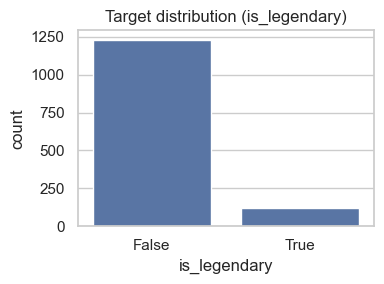

In [5]:
counts = df["is_legendary"].value_counts()
print(counts)
print(f"Legendary share: {counts[True] / len(df):.1%}")

fig, ax = plt.subplots(figsize=(4, 3))
sns.countplot(data=df, x="is_legendary", ax=ax)
ax.set_title("Target distribution (is_legendary)")
plt.tight_layout()
plt.savefig(FIG_DIR / "target_distribution.png", dpi=150)
plt.show()

The target is imbalanced (about 9% Legendary), so **accuracy alone is misleading**: a model that always predicts non-Legendary already scores about 91%. The evaluation therefore focuses on precision, recall and F1 for the Legendary class.

### 3.4 Numeric features and outliers

,count,mean,std,min,25%,50%,75%,max
height_dm,1351.0,20.4,53.2,1.0,6.0,11.0,17.0,1000.0
weight_hg,1351.0,991.1,1953.1,0.0,94.5,326.0,853.5,10000.0
hp,1351.0,71.7,26.8,1.0,55.0,70.0,85.0,255.0
attack,1351.0,82.8,32.4,5.0,60.0,80.0,102.5,190.0
defense,1351.0,76.2,30.7,5.0,55.0,70.0,95.0,250.0
special_attack,1351.0,75.4,34.0,10.0,50.0,69.0,97.0,216.0
special_defense,1351.0,74.1,27.8,20.0,54.0,70.0,90.0,250.0
speed,1351.0,72.0,30.6,5.0,49.0,70.0,95.0,200.0


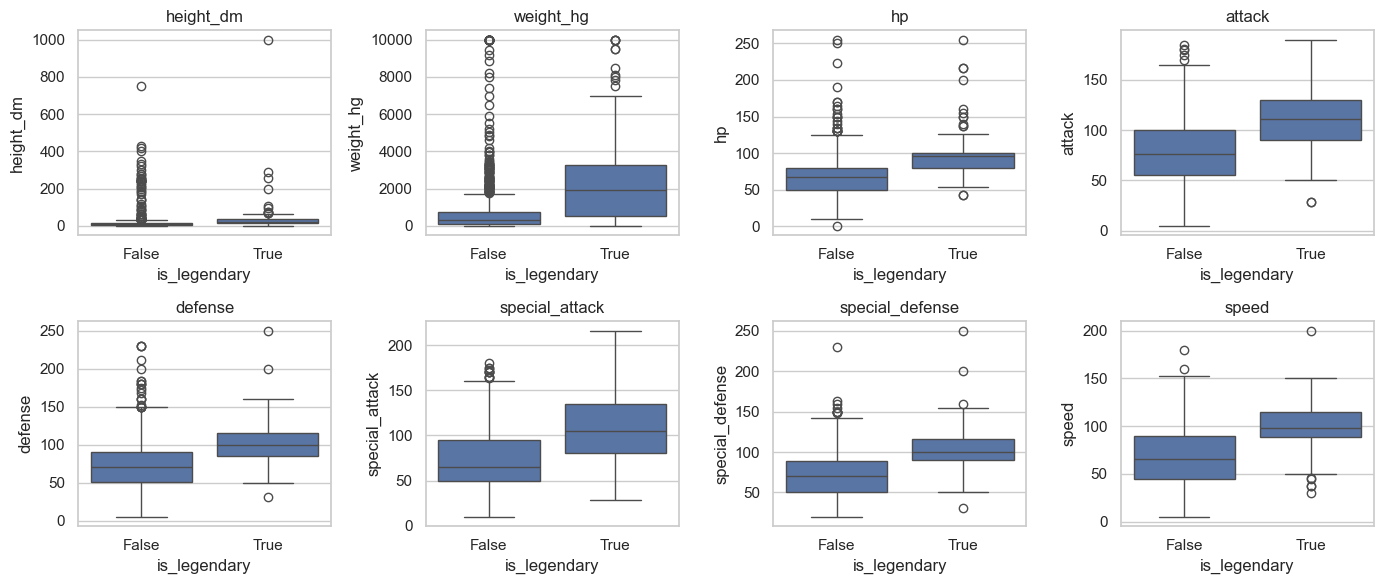

In [6]:
num_cols = ["height_dm", "weight_hg", "hp", "attack", "defense",
            "special_attack", "special_defense", "speed"]
display(df[num_cols].describe().T.round(1))

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="is_legendary", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "numeric_boxplots.png", dpi=150)
plt.show()

In [7]:
# Simple IQR outlier count per numeric column
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)).sum()
outliers.to_frame("n_outliers_IQR")

,n_outliers_IQR
height_dm,95
weight_hg,174
hp,30
attack,10
defense,19
special_attack,14
special_defense,17
speed,2


In [8]:
# Most extreme height / weight values (checking for placeholder or data-entry values)
df.nlargest(5, "height_dm")[["name", "height_dm", "weight_hg"]].merge(
    df.nlargest(5, "weight_hg")[["name", "height_dm", "weight_hg"]], how="outer")

,name,height_dm,weight_hg
0,blastoise-gmax,250,10000
1,butterfree-gmax,170,10000
2,centiskorch-gmax,750,10000
3,charizard-gmax,280,10000
4,coalossal-gmax,420,10000
5,duraludon-gmax,430,10000
6,eternatus-eternamax,1000,0
7,inteleon-gmax,400,10000
8,pikachu-gmax,210,10000
9,venusaur-gmax,240,10000


**Outlier notes.** Many outliers exist but they are real game values (e.g. very large or very heavy Pokémon), and several are Legendary, so they carry signal. They are **kept**. Some weights look like placeholder values (e.g. `9999`), which is a data-quality limitation to mention in the report. Tree-based models are not sensitive to scale, while KNN is, which is why scaling is part of the pipeline.

### 3.5 Categorical features

In [9]:
print("type_1 categories:", df["type_1"].nunique(), "| type_2 categories:", df["type_2"].nunique())
print("generations:", sorted(df["generation"].unique()))
display(pd.crosstab(df["generation"], df["is_legendary"]))

type_1 categories: 18 | type_2 categories: 18
generations: ['generation-i', 'generation-ii', 'generation-iii', 'generation-iv', 'generation-ix', 'generation-v', 'generation-vi', 'generation-vii', 'generation-viii']


is_legendary,False,True
generation,,
generation-i,229,9
generation-ii,110,5
generation-iii,154,13
generation-iv,116,13
generation-ix,125,24
generation-v,171,14
generation-vi,96,8
generation-vii,117,14
generation-viii,113,20


### 3.6 Related columns that need care (possible leakage and label issues)

In [10]:
print(df.groupby("is_legendary")["capture_rate"].describe().round(1))
print()
print(df.groupby("is_legendary")["base_experience"].describe().round(1))
print()
print("is_mythical counts:\n", df["is_mythical"].value_counts())
print("\nOverlap legendary & mythical:", (df["is_legendary"] & df["is_mythical"]).sum())

               count  mean   std  min   25%   50%    75%    max
is_legendary                                                   
False         1231.0  95.4  72.2  3.0  45.0  60.0  127.0  255.0
True           120.0  25.1  66.6  3.0   3.0   3.0    3.0  255.0

               count   mean   std   min    25%    50%    75%    max
is_legendary                                                       
False         1184.0  149.8  73.5  36.0   67.8  159.0  182.0  608.0
True           118.0  284.0  67.5  40.0  261.0  290.0  330.0  563.0

is_mythical counts:
 is_mythical
False    1313
True       38
Name: count, dtype: int64

Overlap legendary & mythical: 0


- `capture_rate`: Legendary Pokémon almost all have a value of 3, so it would act as a near-perfect proxy for the label. It is a game-design property that is effectively *part of the definition* of Legendary, so it is **excluded** to avoid target leakage.
- `base_experience`: also strongly separated by class, and not in the proposed feature set, so it is **excluded**.
- `is_mythical`: a *separate* special-Pokémon flag. Mythical Pokémon are labelled `is_legendary = False` (there is no overlap), so they are treated as negatives. They look statistically similar to Legendaries, which is a known source of label noise and is discussed as a limitation. `is_mythical` itself is **not** used as a feature.
- `name`, `id`: identifiers only, **excluded**. `abilities`, `color`, `shape`: not in the proposed feature set, **excluded** (can be revisited later if justified).

## 4. Train/test split and evaluation design

- **Split:** 80% train / 20% test, **stratified** on `is_legendary` so both sets keep the ~9% Legendary rate. Fixed `random_state` for reproducibility.
- **Test set:** locked away. It is only used once, for the final comparison.
- **Model selection / tuning:** 5-fold **stratified cross-validation on the training set only**.
- **Metrics:** precision, recall and F1 for the Legendary (positive) class, plus accuracy and balanced accuracy for context. Confusion matrix reported for the baseline.
- **Leakage control:** every preprocessing step (imputation, scaling, encoding) lives inside a scikit-learn `Pipeline`, so it is re-fitted on each training fold only.

In [11]:
cat_cols = ["type_1", "type_2", "generation"]
feature_cols = num_cols + cat_cols
target_col = "is_legendary"

X = df[feature_cols].copy()
y = df[target_col].astype(int)

# Treat missing type_2 as its own category (single-type Pokemon)
X["type_2"] = X["type_2"].fillna("none")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape[0]} rows | Legendary: {y_train.sum()} ({y_train.mean():.1%})")
print(f"Test:  {X_test.shape[0]} rows | Legendary: {y_test.sum()} ({y_test.mean():.1%})")

Train: 1080 rows | Legendary: 96 (8.9%)
Test:  271 rows | Legendary: 24 (8.9%)


## 5. Preprocessing pipeline

### 5.1 Features used
Numeric: `height_dm`, `weight_hg`, `hp`, `attack`, `defense`, `special_attack`, `special_defense`, `speed`
Categorical: `type_1`, `type_2` (missing → `"none"`), `generation`
Target: `is_legendary`

In [12]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="none")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

In [13]:
# Sanity check: fit on TRAIN only, then transform both
Xt_train = preprocess.fit_transform(X_train)
Xt_test = preprocess.transform(X_test)
print("Transformed train shape:", Xt_train.shape, "| test shape:", Xt_test.shape)

Transformed train shape: (1080, 54) | test shape: (271, 54)


## 6. Baseline model results

Two `DummyClassifier` baselines: `most_frequent` (always predicts non-Legendary) and `stratified` (random guesses following the class distribution). A simple **logistic regression** is also included as a reference point. It is clearly labelled as a simple sanity-check model, not one of the final candidate models.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

models = {
    "Dummy (most_frequent)": DummyClassifier(strategy="most_frequent"),
    "Dummy (stratified)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "Logistic Regression (reference)": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
}

rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # precision is undefined (0/0) for the always-negative dummy
    for name, clf in models.items():
        pipe = Pipeline([("prep", preprocess), ("model", clf)])
        res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
        rows.append({"model": name, **{m: res[f"test_{m}"].mean() for m in scoring},
                     **{f"{m}_std": res[f"test_{m}"].std() for m in ["f1"]}})

results = pd.DataFrame(rows).set_index("model").round(3)
results

,accuracy,balanced_accuracy,precision,recall,f1,f1_std
model,,,,,,
Dummy (most_frequent),0.911,0.500,0.000,0.000,0.000,0.000
Dummy (stratified),0.853,0.496,0.080,0.063,0.070,0.024
Logistic Regression (reference),0.934,0.714,0.717,0.447,0.535,0.129


**Reading the baseline.** The majority-class dummy reaches roughly 91% accuracy but **0 precision, recall and F1** for Legendary Pokémon. This confirms why accuracy alone is not a suitable metric here. These F1 / recall values are the bar the learned models in Milestone 3 must beat.

               precision    recall  f1-score   support

Not Legendary       0.91      1.00      0.95       984
    Legendary       0.00      0.00      0.00        96

     accuracy                           0.91      1080
    macro avg       0.46      0.50      0.48      1080
 weighted avg       0.83      0.91      0.87      1080



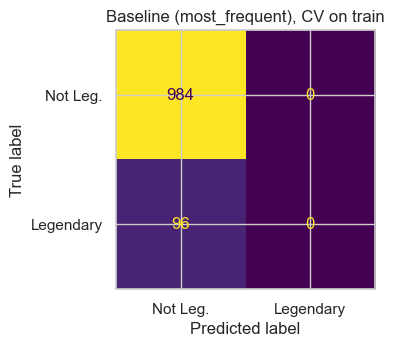

In [15]:
# Confusion matrix for the most-frequent baseline (cross-validated predictions on TRAIN only)
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

base_pipe = Pipeline([("prep", preprocess), ("model", DummyClassifier(strategy="most_frequent"))])
y_pred_cv = cross_val_predict(base_pipe, X_train, y_train, cv=cv)

print(classification_report(y_train, y_pred_cv, target_names=["Not Legendary", "Legendary"], zero_division=0))
fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_cv, display_labels=["Not Leg.", "Legendary"], ax=ax, colorbar=False)
ax.set_title("Baseline (most_frequent), CV on train")
plt.tight_layout()
plt.savefig(FIG_DIR / "baseline_confusion_matrix.png", dpi=150)
plt.show()

## 7. Summary and next steps
- Dataset: 1,351 Pokémon, 11 candidate features, target `is_legendary` (~9% positive).
- Leakage-prone columns (`capture_rate`, `base_experience`) and identifiers are excluded; mythical Pokémon are kept as negatives and flagged as a limitation.
- Evaluation: stratified 80/20 split, test set locked; 5-fold stratified CV on train; precision / recall / F1 on the Legendary class.
- Baseline: the majority-class dummy has 0 F1; the reference logistic regression gives a first realistic benchmark.
- **Milestone 3:** add K-Nearest Neighbours, Decision Tree and Random Forest under the same protocol, with light tuning (CV on train only), plus error analysis.

## Assistance declaration
- Dataset: Kaggle "Pokemon Stats Dataset" (see README for source and licence).
- Generative AI / coding assistant: Claude (Anthropic) was used to help structure this notebook and draft code. I reviewed, ran and understand all code and decisions.
- No external collaboration. No other external code beyond the scikit-learn / pandas / seaborn documentation examples.